[*********************100%***********************]  1 of 1 completed

Fetching S&P 500 data...

--- Extreme Data Removed (Daily Return > 2.0%) ---

--- No. of Extreme Data Removed : 22---
Price             Close Daily_Return
Ticker            ^GSPC             
Date                                
2023-01-06  3895.080078     2.284078
2023-02-21  3997.340088    -2.004123
2024-02-22  5087.029785     2.112288
2024-07-24  5427.129883    -2.314909
2024-08-05  5186.330078    -2.996880
2024-08-08  5319.310059     2.304261
2024-09-03  5528.930176    -2.115107
2024-11-06  5929.040039     2.529593
2024-12-18  5872.160156    -2.949285
2025-03-10  5614.560059    -2.697309
2025-03-14  5638.939941     2.126587
2025-04-03  5396.520020    -4.839563
2025-04-04  5074.080078    -5.974961
2025-04-09  5456.899902     9.515388
2025-04-10  5268.049805    -3.460758
2025-04-16  5275.700195    -2.240837
2025-04-21  5158.200195    -2.356749
2025-04-22  5287.759766     2.511720
2025-04-24  5484.770020     2.025911
2025-05-12  5844.189941     3.255878
2025-05-27  5921.540039     2.0

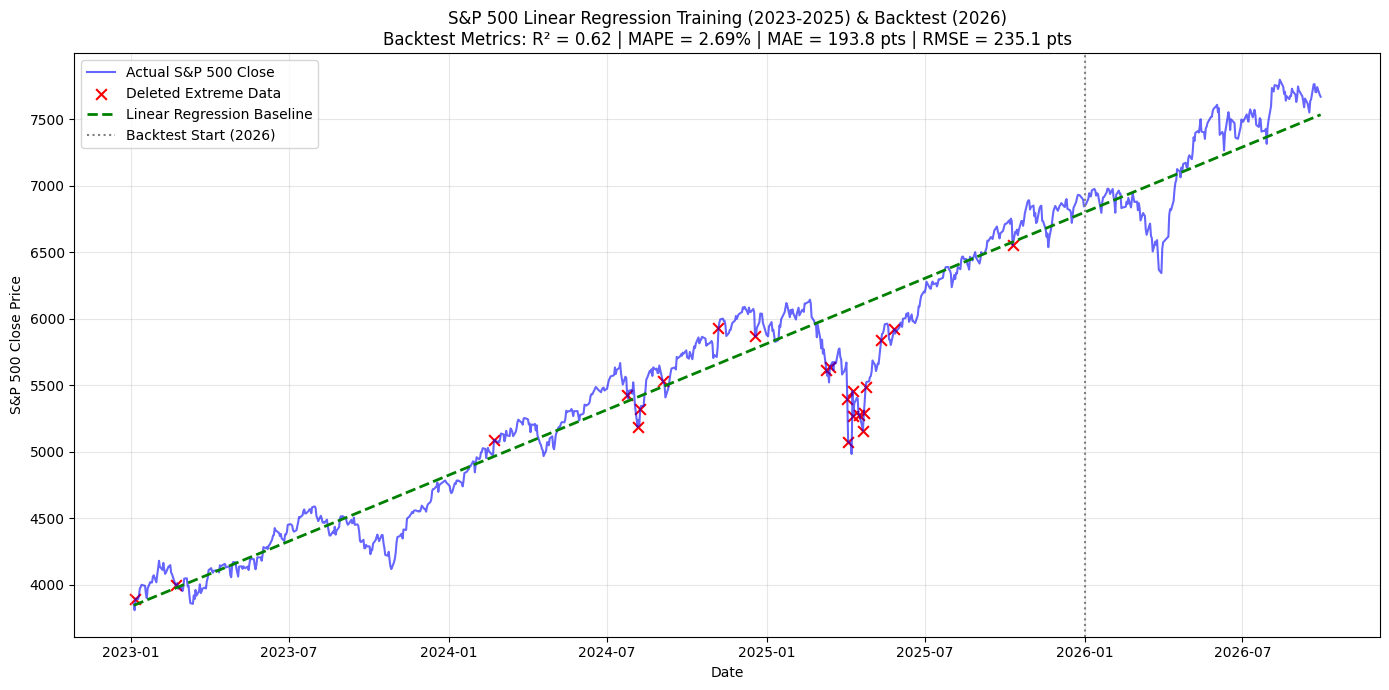

In [7]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
# 💡 引入 MAE, RMSE 和 MAPE 計算函式
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

# 1. Fetch S&P 500 data from yfinance
print("Fetching S&P 500 data...")
df = yf.download('^GSPC', start='2023-01-01', end='2026-09-30')
df['Daily_Return'] = df['Close'].pct_change() * 100
df['Ordinal_Date'] = df.index.map(pd.Timestamp.toordinal)
df = df.dropna()

# 2. Split into Training (2023-2025) and Backtesting (2026) sets
train_df = df.loc['2023-01-01':'2025-12-31'].copy()
test_df = df.loc['2026-01-01':].copy()

# 3. Identify and remove extreme data points (Outliers with absolute daily return > 2%)
volatility_threshold = 2.0
extreme_data = train_df[train_df['Daily_Return'].abs() > volatility_threshold]
clean_train_df = train_df[train_df['Daily_Return'].abs() <= volatility_threshold]

print(f"\n--- Extreme Data Removed (Daily Return > {volatility_threshold}%) ---")
print(f"\n--- No. of Extreme Data Removed : {len(extreme_data)}---")
print(extreme_data[['Close', 'Daily_Return']])

# 4. Train Linear Regression Model
X_train = clean_train_df[['Ordinal_Date']]
y_train = clean_train_df['Close']
X_test = test_df[['Ordinal_Date']]
y_test = test_df['Close']

model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict and Evaluate Backtest Data (2026)
y_pred_test = model.predict(X_test)

# 💡 計算 Backtest 的各項評估指標
r2_backtest = r2_score(y_test, y_pred_test)
mape_backtest = mean_absolute_percentage_error(y_test, y_pred_test) * 100
mae_backtest = mean_absolute_error(y_test, y_pred_test)
rmse_backtest = root_mean_squared_error(y_test, y_pred_test)

print(f"\n--- Backtest (2026) Evaluation Metrics ---")
print(f"R2 Score : {r2_backtest:.4f}")
print(f"MAPE     : {mape_backtest:.2f}%")
print(f"MAE      : {mae_backtest:.2f} points")
print(f"RMSE     : {rmse_backtest:.2f} points")

# 6. Plot the Trends and Predictions
plt.figure(figsize=(14, 7))

# Plot actual prices
plt.plot(df.index, df['Close'], label='Actual S&P 500 Close', color='blue', alpha=0.6)

# Highlight extreme data points removed from training
plt.scatter(extreme_data.index, extreme_data['Close'], color='red', marker='x', s=60, label='Deleted Extreme Data')

# Plot Linear Regression line across both periods
all_X = df[['Ordinal_Date']]
all_pred = model.predict(all_X)
plt.plot(df.index, all_pred, label='Linear Regression Baseline', color='green', linestyle='--', linewidth=2)

# Visual split for the Backtest phase
plt.axvline(pd.to_datetime('2026-01-01'), color='gray', linestyle=':', label='Backtest Start (2026)')

# 💡 在標題中完整呈現 4 個指標
title_text = (f'S&P 500 Linear Regression Training (2023-2025) & Backtest (2026)\n'
              f'Backtest Metrics: R² = {r2_backtest:.2f} | MAPE = {mape_backtest:.2f}% | '
              f'MAE = {mae_backtest:.1f} pts | RMSE = {rmse_backtest:.1f} pts')
plt.title(title_text, fontsize=12)
plt.xlabel('Date')
plt.ylabel('S&P 500 Close Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


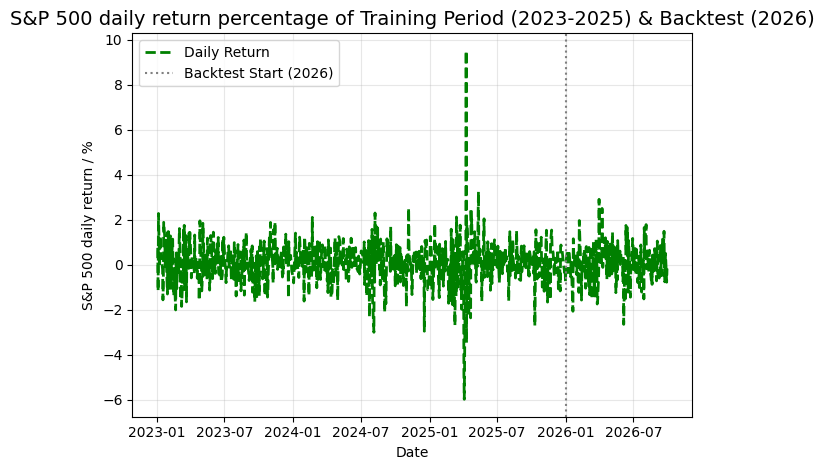

In [8]:
all_X = df[['Ordinal_Date']]
all_pred = df['Daily_Return']
plt.plot(df.index, all_pred, label='Daily Return', color='green', linestyle='--', linewidth=2 )

# Visual split for the Backtest phase
plt.axvline(pd.to_datetime('2026-01-01'), color='gray', linestyle=':', label='Backtest Start (2026)')

plt.title(f'S&P 500 daily return percentage of Training Period (2023-2025) & Backtest (2026)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('S&P 500 daily return / %')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

[*********************100%***********************]  1 of 1 completed

Fetching HSI data...

--- Extreme Data Removed (Daily Return > 2%) ---

--- No. of Extreme Data Removed : 109---
Price              Close Daily_Return
Ticker              ^HSI             
Date                                 
2023-01-04  20793.109375     3.215741
2023-01-26  22566.779297     2.368506
2023-01-30  22069.730469    -2.728955
2023-02-06  21222.160156    -2.023550
2023-02-10  21190.419922    -2.006716
...                  ...          ...
2025-09-01  25617.419922     2.152520
2025-10-17  25247.099609    -2.477586
2025-10-20  25858.830078     2.422973
2025-11-06  26485.900391     2.122543
2025-11-21  25220.019531    -2.382571

[109 rows x 2 columns]

--- Backtest (2026) Evaluation Metrics ---
R2 Score : -1.1489
MAPE     : 4.56%
MAE      : 1170.60 points
RMSE     : 1433.44 points


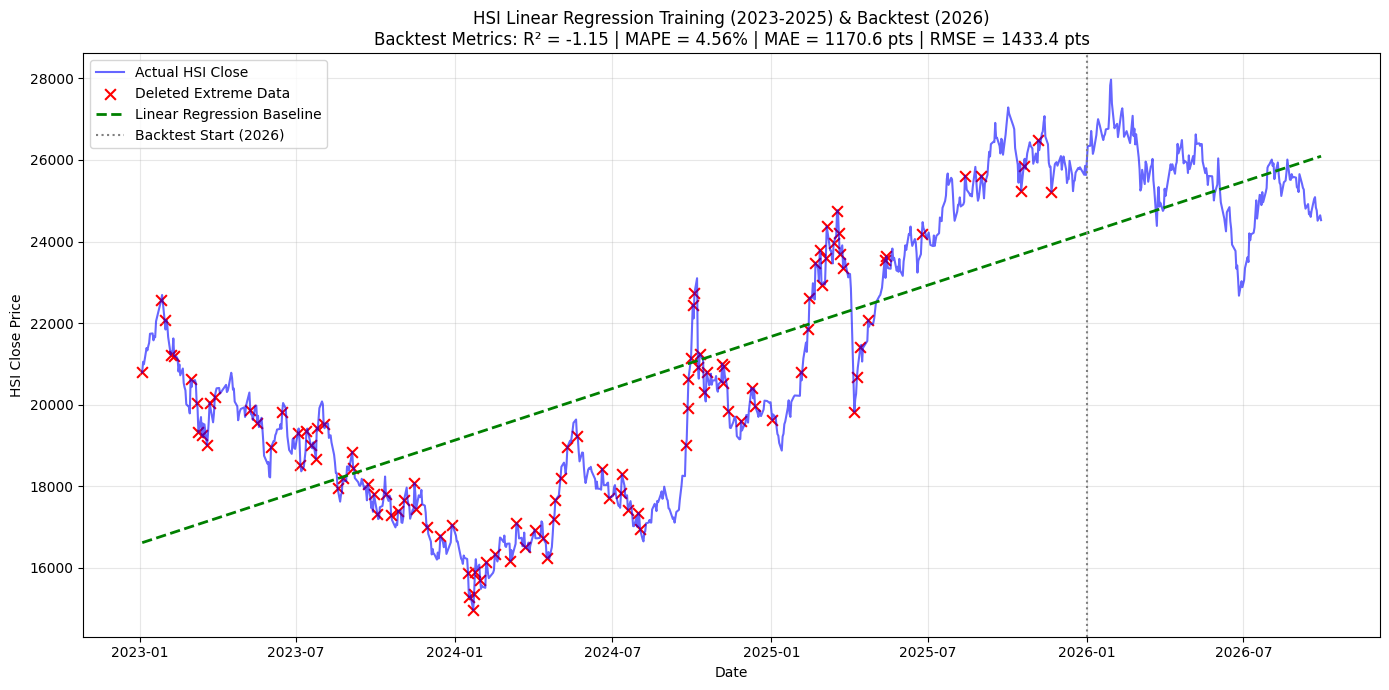

In [9]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
# 💡 引入 MAE, RMSE 和 MAPE 計算函式
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

# 1. Fetch HSI data from yfinance
print("Fetching HSI data...")
df = yf.download('^HSI', start='2023-01-01', end='2026-09-30')
df['Daily_Return'] = df['Close'].pct_change() * 100
df['Ordinal_Date'] = df.index.map(pd.Timestamp.toordinal)
df = df.dropna()

# 2. Split into Training (2023-2025) and Backtesting (2026) sets
train_df = df.loc['2023-01-01':'2025-12-31'].copy()
test_df = df.loc['2026-01-01':].copy()

# 3. Identify and remove extreme data points (Outliers with absolute daily return > 2%)
volatility_threshold = 2
extreme_data = train_df[train_df['Daily_Return'].abs() > volatility_threshold]
clean_train_df = train_df[train_df['Daily_Return'].abs() <= volatility_threshold]

print(f"\n--- Extreme Data Removed (Daily Return > {volatility_threshold}%) ---")
print(f"\n--- No. of Extreme Data Removed : {len(extreme_data)}---")
print(extreme_data[['Close', 'Daily_Return']])

# 4. Train Linear Regression Model
X_train = clean_train_df[['Ordinal_Date']]
y_train = clean_train_df['Close']
X_test = test_df[['Ordinal_Date']]
y_test = test_df['Close']

model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict and Evaluate Backtest Data (2026)
y_pred_test = model.predict(X_test)

# 💡 計算 Backtest 的各項評估指標
r2_backtest = r2_score(y_test, y_pred_test)
mape_backtest = mean_absolute_percentage_error(y_test, y_pred_test) * 100
mae_backtest = mean_absolute_error(y_test, y_pred_test)
rmse_backtest = root_mean_squared_error(y_test, y_pred_test)

print(f"\n--- Backtest (2026) Evaluation Metrics ---")
print(f"R2 Score : {r2_backtest:.4f}")
print(f"MAPE     : {mape_backtest:.2f}%")
print(f"MAE      : {mae_backtest:.2f} points")
print(f"RMSE     : {rmse_backtest:.2f} points")

# 6. Plot the Trends and Predictions
plt.figure(figsize=(14, 7))

# Plot actual prices
plt.plot(df.index, df['Close'], label='Actual HSI Close', color='blue', alpha=0.6)

# Highlight extreme data points removed from training
plt.scatter(extreme_data.index, extreme_data['Close'], color='red', marker='x', s=60, label='Deleted Extreme Data')

# Plot Linear Regression line across both periods
all_X = df[['Ordinal_Date']]
all_pred = model.predict(all_X)
plt.plot(df.index, all_pred, label='Linear Regression Baseline', color='green', linestyle='--', linewidth=2)

# Visual split for the Backtest phase
plt.axvline(pd.to_datetime('2026-01-01'), color='gray', linestyle=':', label='Backtest Start (2026)')

# 💡 在標題中完整呈現 4 個指標
title_text = (f'HSI Linear Regression Training (2023-2025) & Backtest (2026)\n'
              f'Backtest Metrics: R² = {r2_backtest:.2f} | MAPE = {mape_backtest:.2f}% | '
              f'MAE = {mae_backtest:.1f} pts | RMSE = {rmse_backtest:.1f} pts')
plt.title(title_text, fontsize=12)
plt.xlabel('Date')
plt.ylabel('HSI Close Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Fetching 0005 data...


[*********************100%***********************]  1 of 1 completed



--- Extreme Data Removed (Daily Return > 2%) ---

--- No. of Extreme Data Removed : 70---
Price            Close Daily_Return
Ticker         0005.HK             
Date                               
2023-01-04   38.540066     2.669423
2023-01-05   39.503567     2.499998
2023-01-09   41.083710     2.107289
2023-01-13   42.779465     2.587779
2023-01-16   43.665894     2.072090
...                ...          ...
2025-11-21  101.253876    -2.323423
2025-11-24  103.373367     2.093245
2025-12-10  107.612343     2.009133
2025-12-11  109.828171     2.059083
2025-12-12  113.007416     2.894745

[70 rows x 2 columns]

--- Backtest (2026) Evaluation Metrics ---
R2 Score : -5.9523
MAPE     : 25.00%
MAE      : 36.46 points
RMSE     : 37.81 points


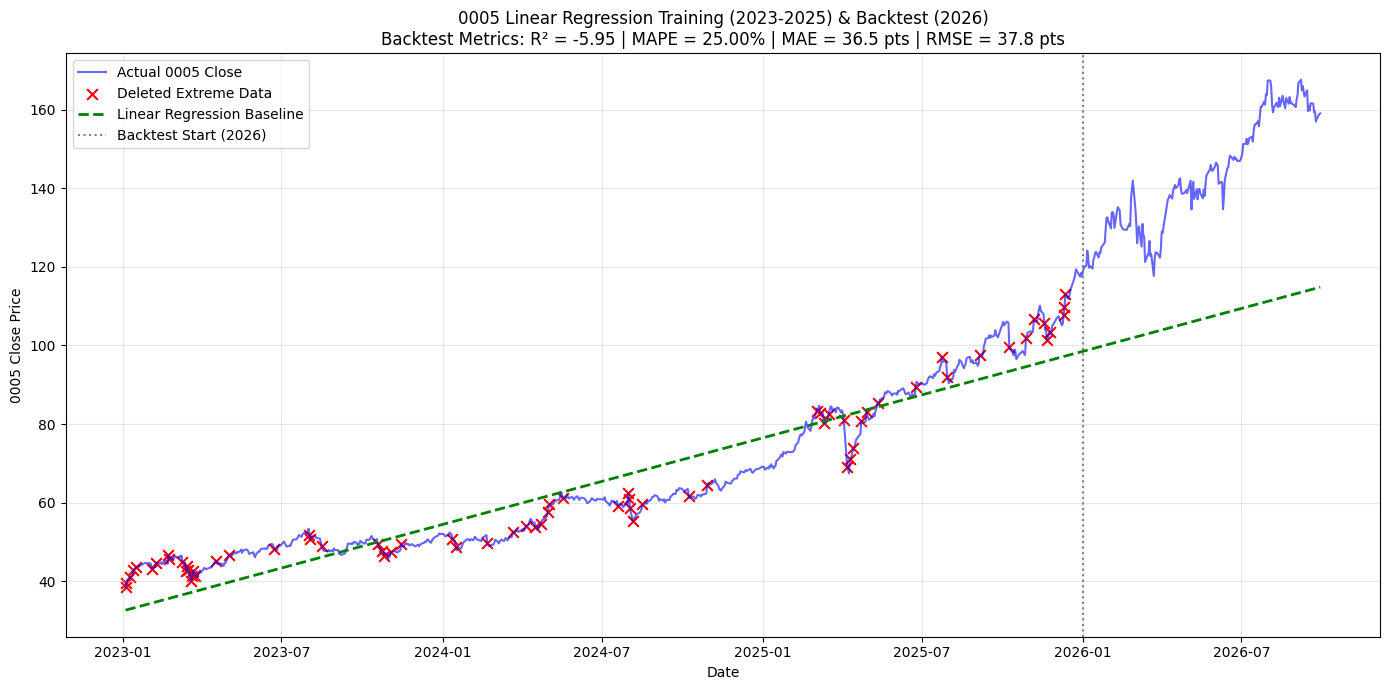

In [10]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
# 💡 引入 MAE, RMSE 和 MAPE 計算函式
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

# 1. Fetch 0005 data from yfinance
print("Fetching 0005 data...")
df = yf.download('0005.HK', start='2023-01-01', end='2026-09-30')
df['Daily_Return'] = df['Close'].pct_change() * 100
df['Ordinal_Date'] = df.index.map(pd.Timestamp.toordinal)
df = df.dropna()

# 2. Split into Training (2023-2025) and Backtesting (2026) sets
train_df = df.loc['2023-01-01':'2025-12-31'].copy()
test_df = df.loc['2026-01-01':].copy()

# 3. Identify and remove extreme data points (Outliers with absolute daily return > 2%)
volatility_threshold = 2
extreme_data = train_df[train_df['Daily_Return'].abs() > volatility_threshold]
clean_train_df = train_df[train_df['Daily_Return'].abs() <= volatility_threshold]

print(f"\n--- Extreme Data Removed (Daily Return > {volatility_threshold}%) ---")
print(f"\n--- No. of Extreme Data Removed : {len(extreme_data)}---")
print(extreme_data[['Close', 'Daily_Return']])

# 4. Train Linear Regression Model
X_train = clean_train_df[['Ordinal_Date']]
y_train = clean_train_df['Close']
X_test = test_df[['Ordinal_Date']]
y_test = test_df['Close']

model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict and Evaluate Backtest Data (2026)
y_pred_test = model.predict(X_test)

# 💡 計算 Backtest 的各項評估指標
r2_backtest = r2_score(y_test, y_pred_test)
mape_backtest = mean_absolute_percentage_error(y_test, y_pred_test) * 100
mae_backtest = mean_absolute_error(y_test, y_pred_test)
rmse_backtest = root_mean_squared_error(y_test, y_pred_test)

print(f"\n--- Backtest (2026) Evaluation Metrics ---")
print(f"R2 Score : {r2_backtest:.4f}")
print(f"MAPE     : {mape_backtest:.2f}%")
print(f"MAE      : {mae_backtest:.2f} points")
print(f"RMSE     : {rmse_backtest:.2f} points")

# 6. Plot the Trends and Predictions
plt.figure(figsize=(14, 7))

# Plot actual prices
plt.plot(df.index, df['Close'], label='Actual 0005 Close', color='blue', alpha=0.6)

# Highlight extreme data points removed from training
plt.scatter(extreme_data.index, extreme_data['Close'], color='red', marker='x', s=60, label='Deleted Extreme Data')

# Plot Linear Regression line across both periods
all_X = df[['Ordinal_Date']]
all_pred = model.predict(all_X)
plt.plot(df.index, all_pred, label='Linear Regression Baseline', color='green', linestyle='--', linewidth=2)

# Visual split for the Backtest phase
plt.axvline(pd.to_datetime('2026-01-01'), color='gray', linestyle=':', label='Backtest Start (2026)')

# 💡 在標題中完整呈現 4 個指標
title_text = (f'0005 Linear Regression Training (2023-2025) & Backtest (2026)\n'
              f'Backtest Metrics: R² = {r2_backtest:.2f} | MAPE = {mape_backtest:.2f}% | '
              f'MAE = {mae_backtest:.1f} pts | RMSE = {rmse_backtest:.1f} pts')
plt.title(title_text, fontsize=12)
plt.xlabel('Date')
plt.ylabel('0005 Close Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Fetching 0388 data...


[*********************100%***********************]  1 of 1 completed



--- Extreme Data Removed (Daily Return > 4%) ---

--- No. of Extreme Data Removed : 39---
Price            Close Daily_Return
Ticker         0388.HK             
Date                               
2023-01-09  334.248901     4.139076
2023-02-06  298.999573    -4.199750
2023-03-01  292.977020     5.149393
2023-07-13  271.502075     4.335860
2023-07-25  274.009338     5.444533
2023-07-28  290.306610     5.259741
2023-08-29  279.494843     5.022186
2023-10-25  252.945602    -4.068960
2023-12-04  244.035217    -4.074337
2023-12-05  230.578751    -5.514149
2023-12-15  236.215897     4.421211
2024-01-23  212.212433     5.324910
2024-02-06  221.486526     5.637481
2024-04-23  213.185364     4.909088
2024-05-02  244.590485     5.246418
2024-05-10  263.987732     7.605404
2024-09-19  224.147644     5.772654
2024-09-24  243.532349     7.385879
2024-09-26  261.599640     5.864417
2024-09-27  290.394470    11.007213
2024-09-30  306.956207     5.703186
2024-10-02  350.807007    14.285686
2024-10-0

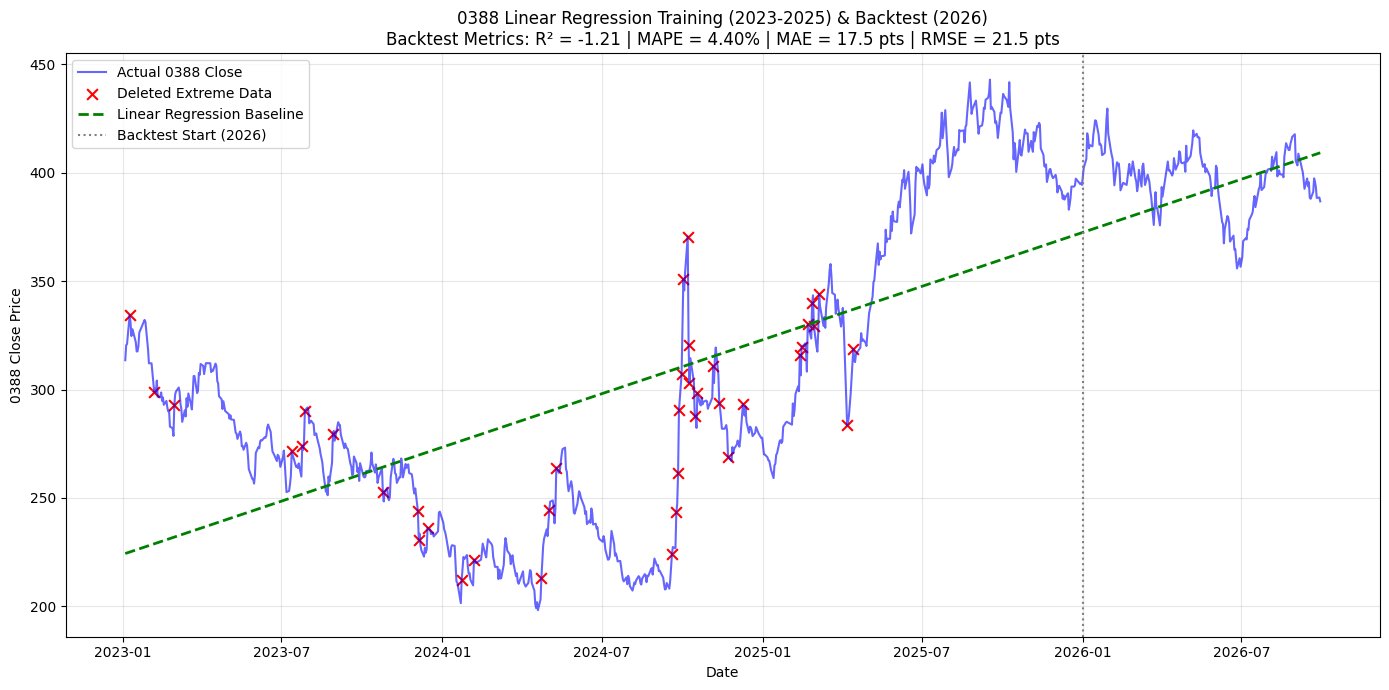

In [11]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
# 💡 引入 MAE, RMSE 和 MAPE 計算函式
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

# 1. Fetch 0388 data from yfinance
print("Fetching 0388 data...")
df = yf.download('0388.HK', start='2023-01-01', end='2026-09-30')
df['Daily_Return'] = df['Close'].pct_change() * 100
df['Ordinal_Date'] = df.index.map(pd.Timestamp.toordinal)
df = df.dropna()

# 2. Split into Training (2023-2025) and Backtesting (2026) sets
train_df = df.loc['2023-01-01':'2025-12-31'].copy()
test_df = df.loc['2026-01-01':].copy()

# 3. Identify and remove extreme data points (Outliers with absolute daily return > 2%)
volatility_threshold = 4
extreme_data = train_df[train_df['Daily_Return'].abs() > volatility_threshold]
clean_train_df = train_df[train_df['Daily_Return'].abs() <= volatility_threshold]

print(f"\n--- Extreme Data Removed (Daily Return > {volatility_threshold}%) ---")
print(f"\n--- No. of Extreme Data Removed : {len(extreme_data)}---")
print(extreme_data[['Close', 'Daily_Return']])

# 4. Train Linear Regression Model
X_train = clean_train_df[['Ordinal_Date']]
y_train = clean_train_df['Close']
X_test = test_df[['Ordinal_Date']]
y_test = test_df['Close']

model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict and Evaluate Backtest Data (2026)
y_pred_test = model.predict(X_test)

# 💡 計算 Backtest 的各項評估指標
r2_backtest = r2_score(y_test, y_pred_test)
mape_backtest = mean_absolute_percentage_error(y_test, y_pred_test) * 100
mae_backtest = mean_absolute_error(y_test, y_pred_test)
rmse_backtest = root_mean_squared_error(y_test, y_pred_test)

print(f"\n--- Backtest (2026) Evaluation Metrics ---")
print(f"R2 Score : {r2_backtest:.4f}")
print(f"MAPE     : {mape_backtest:.2f}%")
print(f"MAE      : {mae_backtest:.2f} points")
print(f"RMSE     : {rmse_backtest:.2f} points")

# 6. Plot the Trends and Predictions
plt.figure(figsize=(14, 7))

# Plot actual prices
plt.plot(df.index, df['Close'], label='Actual 0388 Close', color='blue', alpha=0.6)

# Highlight extreme data points removed from training
plt.scatter(extreme_data.index, extreme_data['Close'], color='red', marker='x', s=60, label='Deleted Extreme Data')

# Plot Linear Regression line across both periods
all_X = df[['Ordinal_Date']]
all_pred = model.predict(all_X)
plt.plot(df.index, all_pred, label='Linear Regression Baseline', color='green', linestyle='--', linewidth=2)

# Visual split for the Backtest phase
plt.axvline(pd.to_datetime('2026-01-01'), color='gray', linestyle=':', label='Backtest Start (2026)')

# 💡 在標題中完整呈現 4 個指標
title_text = (f'0388 Linear Regression Training (2023-2025) & Backtest (2026)\n'
              f'Backtest Metrics: R² = {r2_backtest:.2f} | MAPE = {mape_backtest:.2f}% | '
              f'MAE = {mae_backtest:.1f} pts | RMSE = {rmse_backtest:.1f} pts')
plt.title(title_text, fontsize=12)
plt.xlabel('Date')
plt.ylabel('0388 Close Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Fetching 0386 data...


[*********************100%***********************]  1 of 1 completed


--- Extreme Data Removed (Daily Return > 4%) ---

--- No. of Extreme Data Removed : 20---
Price          Close Daily_Return
Ticker       0386.HK             
Date                             
2023-03-03  3.324668     4.066993
2023-03-07  3.584528     4.222204
2023-03-13  3.660957     5.739510
2023-03-17  3.745029     6.060620
2023-03-20  3.576885    -4.489804
2023-05-08  4.111889     5.905521
2023-10-03  3.353570    -5.140174
2024-01-24  3.188369     4.324326
2024-01-25  3.419649     7.253876
2024-04-02  3.849170     4.954935
2024-05-10  4.204352     5.383034
2024-07-17  4.135691    -4.382466
2024-08-27  4.678500     5.232548
2024-09-05  4.135367    -6.073886
2024-09-09  3.904142    -5.591402
2024-10-02  4.624496     7.438007
2024-10-08  4.428845    -8.287288
2025-04-07  3.343867    -8.292686
2025-07-21  4.224501     5.529953
2025-08-01  3.993905    -5.869569

--- Backtest (2026) Evaluation Metrics ---
R2 Score : -0.7374
MAPE     : 7.03%
MAE      : 0.33 points
RMSE     : 0.45 points


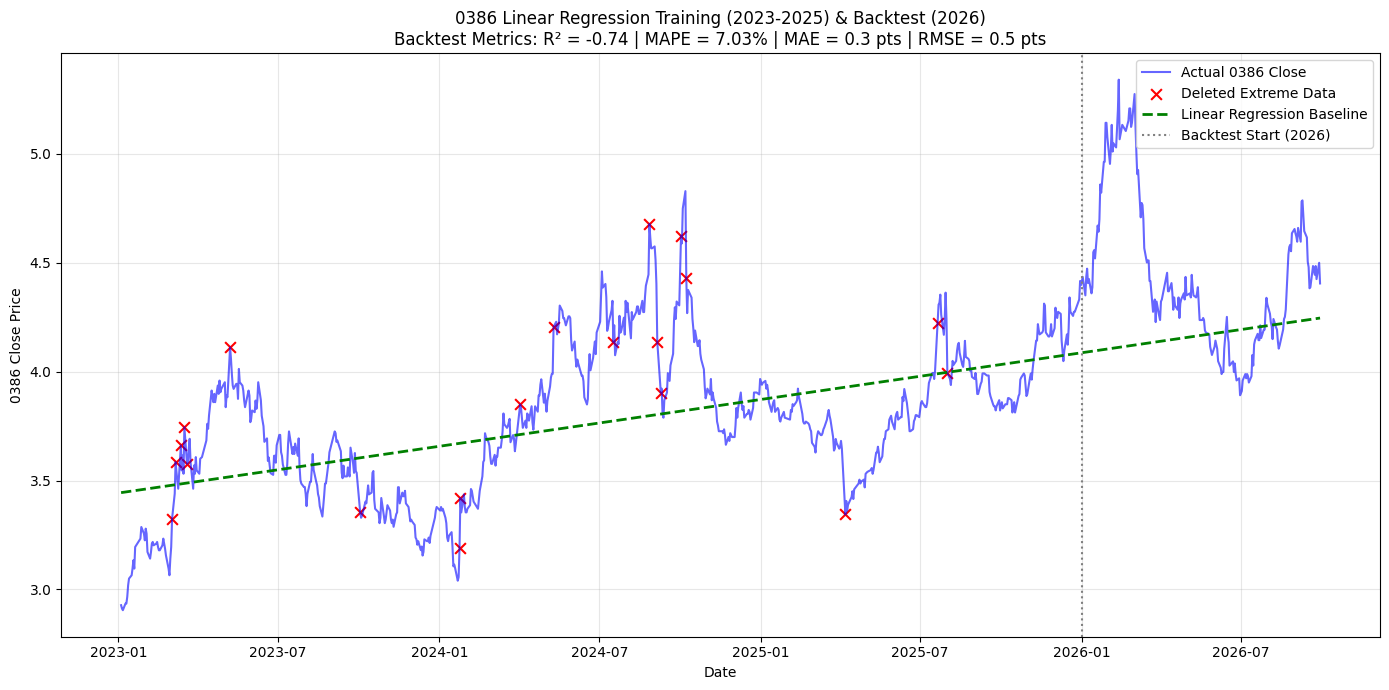

In [12]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
# 💡 引入 MAE, RMSE 和 MAPE 計算函式
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

# 1. Fetch 0386 data from yfinance
print("Fetching 0386 data...")
df = yf.download('0386.HK', start='2023-01-01', end='2026-09-30')
df['Daily_Return'] = df['Close'].pct_change() * 100
df['Ordinal_Date'] = df.index.map(pd.Timestamp.toordinal)
df = df.dropna()

# 2. Split into Training (2023-2025) and Backtesting (2026) sets
train_df = df.loc['2023-01-01':'2025-12-31'].copy()
test_df = df.loc['2026-01-01':].copy()

# 3. Identify and remove extreme data points (Outliers with absolute daily return > 2%)
volatility_threshold = 4
extreme_data = train_df[train_df['Daily_Return'].abs() > volatility_threshold]
clean_train_df = train_df[train_df['Daily_Return'].abs() <= volatility_threshold]

print(f"\n--- Extreme Data Removed (Daily Return > {volatility_threshold}%) ---")
print(f"\n--- No. of Extreme Data Removed : {len(extreme_data)}---")
print(extreme_data[['Close', 'Daily_Return']])

# 4. Train Linear Regression Model
X_train = clean_train_df[['Ordinal_Date']]
y_train = clean_train_df['Close']
X_test = test_df[['Ordinal_Date']]
y_test = test_df['Close']

model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict and Evaluate Backtest Data (2026)
y_pred_test = model.predict(X_test)

# 💡 計算 Backtest 的各項評估指標
r2_backtest = r2_score(y_test, y_pred_test)
mape_backtest = mean_absolute_percentage_error(y_test, y_pred_test) * 100
mae_backtest = mean_absolute_error(y_test, y_pred_test)
rmse_backtest = root_mean_squared_error(y_test, y_pred_test)

print(f"\n--- Backtest (2026) Evaluation Metrics ---")
print(f"R2 Score : {r2_backtest:.4f}")
print(f"MAPE     : {mape_backtest:.2f}%")
print(f"MAE      : {mae_backtest:.2f} points")
print(f"RMSE     : {rmse_backtest:.2f} points")

# 6. Plot the Trends and Predictions
plt.figure(figsize=(14, 7))

# Plot actual prices
plt.plot(df.index, df['Close'], label='Actual 0386 Close', color='blue', alpha=0.6)

# Highlight extreme data points removed from training
plt.scatter(extreme_data.index, extreme_data['Close'], color='red', marker='x', s=60, label='Deleted Extreme Data')

# Plot Linear Regression line across both periods
all_X = df[['Ordinal_Date']]
all_pred = model.predict(all_X)
plt.plot(df.index, all_pred, label='Linear Regression Baseline', color='green', linestyle='--', linewidth=2)

# Visual split for the Backtest phase
plt.axvline(pd.to_datetime('2026-01-01'), color='gray', linestyle=':', label='Backtest Start (2026)')

# 💡 在標題中完整呈現 4 個指標
title_text = (f'0386 Linear Regression Training (2023-2025) & Backtest (2026)\n'
              f'Backtest Metrics: R² = {r2_backtest:.2f} | MAPE = {mape_backtest:.2f}% | '
              f'MAE = {mae_backtest:.1f} pts | RMSE = {rmse_backtest:.1f} pts')
plt.title(title_text, fontsize=12)
plt.xlabel('Date')
plt.ylabel('0386 Close Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()